# Workshop: Semantic Matching with Sentence Transformers
### Case Study: Matching Trade-Association Descriptions to ISIC Industry Codes

## Introduction

In this workshop, we will build a semantic-search pipeline that matches the focus categories of each trade association to the most relevant **International Standard Industrial Classification (ISIC)** description.

The input phrases and the ISIC descriptions do not always share the same words. A sentence transformer helps by representing each text or phrase as a numeric **embedding** that captures aspects of its meaning. We can then compare a query embedding with every ISIC-description embedding and retrieve the closest matches.

## When is semantic matching useful?

Semantic matching can be useful when:

- the same idea can be written with different vocabulary,
- short labels must be matched to longer descriptions,
- exact keyword rules would require too many exceptions

Semantic matching produces **candidate matches** to investigate, not automatically verified labels. This notebook focuses on generating and diagnosing those candidate matches. Human review and evaluation against reviewed ISIC codes are completed in a separate notebook.

For any pipeline that is not completely verifiable be cognizant of the amount humans need to do. Our project has 390 trade categories to review. Review will take some not small amount of time but it is feasible. For projects with thousands or hundreds of thousands of reviews, a modified semantic matching or even a different strategy completely could be a better option.


## Workshop Plan

This workshop follows the same build-small-then-scale-up structure used in the document-scraping curriculum.

### Steps

We will:

1. Explain sentence embeddings and cosine similarity.
2. Distinguish symmetric similarity from asymmetric semantic search.
3. Run a small example with one query and a few candidate documents.
4. Inspect and prepare the association and ISIC datasets.
5. Build a reusable top-\(k\) semantic-matching function.
6. Test the function on a small pilot.
7. Run and compare four sentence-transformer models.
8. Examine similarity scores, score gaps, agreement between models.


## Core Python Libraries

- **pathlib**: portable project, data, model-cache, and output paths
- **pandas**: load, reshape, compare, and save tabular results
- **numpy**: vector operations and reproducible sampling
- **sentence-transformers**: load embedding models, encode text, and run semantic search
- **scikit-learn**: demonstrate cosine similarity
- **torch**: select CPU/GPU execution and clear GPU memory

## Environment

We will work step-by-step in a Jupyter Notebook, so each stage is:

- explained in markdown,
- implemented in code,
- checked with intermediate outputs,
- and evaluated with appropriate metrics.

The first model load downloads its weights unless the model is already cached.


In [91]:
# Run this once when creating a new environment, then restart the kernel.
# In Jupyter/Colab, remove the leading "# " before %pip.
#
# %pip install -U sentence-transformers pandas numpy scikit-learn tqdm matplotlib


In [92]:
from pathlib import Path
from itertools import combinations
from time import perf_counter
import gc
import importlib.metadata as importlib_metadata

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plts

from sentence_transformers import SentenceTransformer, util
from sklearn.metrics.pairwise import cosine_similarity

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_colwidth", 160)

print("sentence-transformers:", importlib_metadata.version("sentence-transformers"))
print("pandas:", pd.__version__)
print("torch:", torch.__version__)
print("Device available:", "cuda" if torch.cuda.is_available() else "cpu")


sentence-transformers: 5.6.0
pandas: 3.0.3
torch: 2.12.1+cpu
Device available: cpu


## Setup: queries, documents, and ranked matches

In this project:

- A **query** is the cleaned association name plus its focus, such as  
  `"confederation of albanian trade unions labour unions"`.
- A **document** is one full ISIC class description, such as  
  `"Activities of trade unions ... promoting the interests of organized labor ..."`.
- A **match** is an ISIC document returned for a query.

The pipeline is a retrieval task: many short queries are searched against the same fixed corpus of 422 ISIC descriptions. This means we can encode the ISIC corpus once per model and reuse those document embeddings for all queries.


## Concept 1: What is a sentence embedding?

A sentence transformer converts variable-length text into a fixed-length numeric vector:

$$
\text{Text } [x_1, x_2, \ldots, x_d]
$$

Texts with related meanings should be located closer together in the model's embedding space. Real embedding dimensions are learned and are not individually labeled. The small example below uses named dimensions only to make the geometry visible.


In [93]:
# A hand-built 3-dimensional illustration.
# # Shows example of how a Sentence Transformer may perform

toy_query = np.array([[0.95, 0.05, 0.00]])

toy_documents = pd.DataFrame(
    {
        "document": [
            "Activities of trade unions",
            "Publishing of newspapers",
            "Hotels and restaurants",
        ],
        "labor_dimension": [0.90, 0.05, 0.10],
        "publishing_dimension": [0.10, 0.95, 0.05],
        "hospitality_dimension": [0.00, 0.05, 0.90],
    }
)

# 
toy_document_vectors = toy_documents[
    ["labor_dimension", "publishing_dimension", "hospitality_dimension"]
].to_numpy()

toy_documents["cosine_similarity"] = cosine_similarity(
    toy_query,
    toy_document_vectors,
)[0]

display(toy_documents.sort_values("cosine_similarity", ascending=False))


,document,labor_dimension,publishing_dimension,hospitality_dimension,cosine_similarity
0,Activities of trade unions,0.90,0.10,0.00,0.998314
2,Hotels and restaurants,0.10,0.05,0.90,0.113009
1,Publishing of newspapers,0.05,0.95,0.05,0.104828


The toy query points mostly in the artificial "labor" direction, so the trade-union document receives the largest cosine similarity.

The real model uses hundreds of learned dimensions and captures much richer language patterns. The retrieval logic is still the same:

1. encode query text,
2. encode document text,
3. calculate similarity,
4. sort from largest to smallest,
5. keep the top-\(k\) candidates.


## Concept 2: Symmetric vs. asymmetric semantic search

**Symmetric similarity** compares texts that have similar roles and lengths, such as two paraphrased sentences.

**Asymmetric semantic search** compares different kinds of text, such as:

- a short query or label, and
- a longer passage that may answer or describe it.

| Symmetric similarity | Asymmetric semantic search |
|---|---|
| Compares texts with the **same role** and usually similar lengths. | Compares texts with **different roles** and often different lengths. |
| “The union represents workers.”<br>↔<br>“Workers are represented by the union.” | **Query:** “labor union”<br>→<br>**Document:** “Activities of trade unions and representation of organized labor.” |
| Both texts are treated equally. | A short query is used to retrieve a longer document. |

Our association-to-ISIC task is mostly asymmetric: the association name/focus is short, while the ISIC entry is a longer class description.

For retrieval tasks, current Sentence Transformers guidance recommends:

- `model.encode_query(...)` for queries
- `model.encode_document(...)` for the document corpus

Models that do not use separate query/document prompts may return the same embeddings as the general `encode(...)` method, but the query/document methods make the intended roles explicit.

For more information, see the [semantic-search guide](https://www.sbert.net/examples/sentence_transformer/applications/semantic-search/README.html) and [encoding usage guide](https://www.sbert.net/docs/sentence_transformer/usage/usage.html).


## Concept 3: Cosine similarity, normalization, and top-\(k\)

Cosine similarity compares the **direction** of two vectors:

$$
\cos(\theta)=\frac{\mathbf{q}\cdot\mathbf{d}}
{\|\mathbf{q}\|\,\|\mathbf{d}\|}
$$

In this notebook we set `normalize_embeddings=True`, so each vector has length 1. For unit-length vectors:

$$
\mathbf{q}\cdot\mathbf{d}=\cos(\theta)
$$

That is why the pipeline can use the fast `util.dot_score` function while interpreting the result as cosine similarity.

Two useful outputs are:

- **top similarity score**: the rank-1 score
- **rank-1/rank-2 score gap**: how far the first candidate is ahead of the second

A small gap identifies an ambiguous ranking, but neither value is a probability of correctness. Score scales can also differ across models.


In [94]:
# live semantic-search example

demo_model_name = "sentence-transformers/multi-qa-MiniLM-L6-cos-v1"
demo_model = SentenceTransformer(demo_model_name)

# Using only a single query for example
demo_query = ["newspapers editors association"]
demo_documents = [
    "Activities of trade unions and representation of organized labor.",
    "Publishing of newspapers, journals and periodicals in print or electronic form.",
    "Hotels and similar accommodation activities.",
    "Advertising services, media planning and placement of advertisements.",
]

demo_document_embeddings = demo_model.encode_document(
    demo_documents,
    convert_to_numpy=True,
    normalize_embeddings=True,
)
demo_query_embeddings = demo_model.encode_query(
    demo_query,
    convert_to_numpy=True,
    normalize_embeddings=True,
)

demo_hits = util.semantic_search(
    demo_query_embeddings,
    demo_document_embeddings,
    top_k=len(demo_documents),
    score_function=util.dot_score,
)[0]

demo_results = pd.DataFrame(
    [
        {
            "rank": rank,
            "score": float(hit["score"]),
            "document": demo_documents[hit["corpus_id"]],
        }
        for rank, hit in enumerate(demo_hits, start=1)
    ]
)

display(demo_results)

del demo_model, demo_document_embeddings, demo_query_embeddings
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

,rank,score,document
0,1,0.515977,"Publishing of newspapers, journals and periodicals in print or electronic form."
1,2,0.262578,Activities of trade unions and representation of organized labor.
2,3,0.256111,"Advertising services, media planning and placement of advertisements."
3,4,0.146546,Hotels and similar accommodation activities.


The small example shows the complete retrieval operation. The model does not return an ISIC label directly. It returns the indices and scores of the closest documents; we use each returned `corpus_id` to recover the corresponding document and ISIC code.

For the output we see that ["newspapers editors association"] is most similar to "Publishing of newspapers, journals and periodicals in print or electronic form.", which is the expected result.


## Project folders and other setup

Notebook suggested project folder structure
 
```text
project/
  data/
    processed/
    outputs/
  models/
  notebooks/
    this_notebook.ipynb
```

`Path.cwd().parent` points from the notebook folder to the project root. If your notebook is saved elsewhere, replace `PROJECT_DIR` with the correct project path.


In [95]:
PROJECT_DIR = Path.cwd().parent
PROJECT_DIR = Path(r"C:\Users\Joey\Desktop\github\KDSC_Trade_2026\isic_semantic_matching")

DATA_PROCESSED = PROJECT_DIR / "data" / "processed"
DATA_OUTPUTS = PROJECT_DIR / "data" / "outputs"
MODELS_DIR = PROJECT_DIR / "models"

DATA_OUTPUTS.mkdir(parents=True, exist_ok=True)
MODELS_DIR.mkdir(parents=True, exist_ok=True)

print("Project directory:", PROJECT_DIR)
print("Processed data folder:", DATA_PROCESSED)
print("Outputs folder:", DATA_OUTPUTS)
print("Models folder:", MODELS_DIR)


Project directory: C:\Users\Joey\Desktop\github\KDSC_Trade_2026\isic_semantic_matching
Processed data folder: C:\Users\Joey\Desktop\github\KDSC_Trade_2026\isic_semantic_matching\data\processed
Outputs folder: C:\Users\Joey\Desktop\github\KDSC_Trade_2026\isic_semantic_matching\data\outputs
Models folder: C:\Users\Joey\Desktop\github\KDSC_Trade_2026\isic_semantic_matching\models


## Step 1: Load and inspect the project data

The semantic-matching pipeline requires two core files:

1. `unique_name_focus_categories.csv` supplies the association queries.
2. `isic_descriptions_cleaned.csv` supplies the ISIC document corpus.

The original analysis also loads `unique_focus_categories.csv` and `associations_cleaned.csv`. We retain them as optional project context, but the retrieval function does not need them.

ISIC codes are read as strings so codes such as `0111` keep their leading zero.


In [96]:
query_path = DATA_PROCESSED / "unique_name_focus_categories.csv"
isic_path = DATA_PROCESSED / "isic_descriptions_cleaned.csv"
focus_path = DATA_PROCESSED / "unique_focus_categories.csv"
associations_path = DATA_PROCESSED / "associations_cleaned.csv"

required_paths = [query_path, isic_path]
missing_paths = [path for path in required_paths if not path.exists()]

if missing_paths:
    missing_text = "\n".join(f"- {path}" for path in missing_paths)
    raise FileNotFoundError(
        "Required processed-data files were not found:\n"
        f"{missing_text}\n"
        "Update PROJECT_DIR or place the files in data/processed."
    )

df_unique_name_focus = pd.read_csv(query_path)
df_isic = pd.read_csv(isic_path, dtype={"ISIC": "string"})

# Optional context files from the original analysis
df_unique_focus = pd.read_csv(focus_path) if focus_path.exists() else None
df_associations = (
    pd.read_csv(associations_path)
    if associations_path.exists()
    else None
)


In [97]:
print("Unique name + focus categories:", df_unique_name_focus.shape)
print("ISIC descriptions:", df_isic.shape)
print(
    "Unique focus categories:",
    None if df_unique_focus is None else df_unique_focus.shape,
)
print(
    "Associations:",
    None if df_associations is None else df_associations.shape,
)

display(df_unique_name_focus.head())
display(df_isic.head())

print("\nQuery columns:")
print(df_unique_name_focus.columns.tolist())

print("\nISIC columns:")
print(df_isic.columns.tolist())


Unique name + focus categories: (26757, 6)
ISIC descriptions: (422, 3)
Unique focus categories: (23369, 3)
Associations: (23477, 10)


,id,name_English,focus_full,expanded_focus,number_focus,name_focus_english_full_cleaned
0,1,Confederation of Albanian Trade Unions,Labour Unions,Labour Unions,1,confederation of albanian trade unions labour unions
1,2,Newspapers Editors' Association,Newspapers,Newspapers,1,newspapers editors association newspapers
2,3,National Association of Metal Packaging Manufacturers and End-Users,Packaging,Packaging,1,national association of metal packaging manufacturers and end users packaging
3,4,National Hotels' and Restaurants' Association,"Restaurants, Hotels","Restaurants, Hotels",1,national hotels and restaurants association restaurants hotels
4,5,National Algerian Institute of Foreign Trade,Commerce,Commerce,1,national algerian institute of foreign trade commerce


,Text Block,ISIC,description
0,"0111 Growing of cereals (except rice), leguminous crops and oil seeds\nThis class includes all forms of growing of cereals, leguminous crops and oil seeds i...",0111,"Growing of cereals (except rice), leguminous crops and oil seeds\nThis class includes all forms of growing of cereals, leguminous crops and oil seeds in ope..."
1,0112 Growing of rice\nThis class includes:\n— growing of rice (including organic farming and the growing of genetically modified\nrice),0112,Growing of rice\nThis class includes:\n— growing of rice (including organic farming and the growing of genetically modified\nrice)
2,"0113 Growing of vegetables and melons, roots and tubers\nThis class includes:\n— growing of leafy or stem vegetables such as:\n artichokes\n asparagus\n ...",0113,"Growing of vegetables and melons, roots and tubers\nThis class includes:\n— growing of leafy or stem vegetables such as:\n artichokes\n asparagus\n cabba..."
3,0114 Growing of sugar cane\nThis class includes:\n— growing of sugar cane,0114,Growing of sugar cane\nThis class includes:\n— growing of sugar cane
4,0115 Growing of tobacco\nThis class includes:\n— growing of unmanufactured tobacco,0115,Growing of tobacco\nThis class includes:\n— growing of unmanufactured tobacco



Query columns:
['id', 'name_English', 'focus_full', 'expanded_focus', 'number_focus', 'name_focus_english_full_cleaned']

ISIC columns:
['Text Block', 'ISIC', 'description']


## Inspect the query and ISIC data

We can now inspect the text that will be passed through the models.

The query data contains both the original trade-association information and cleaned text prepared for semantic search. Although we could use `expanded_focus` by itself as the query, the association name can provide additional information for the semantic search. We therefore combine the cleaned association name with its expanded focus category in `name_focus_english_full_cleaned`. This combined text will be used as the query.

Semantic search compares meaning rather than requiring the query and target to contain exactly the same words. Including both the association name and focus may therefore help the model distinguish between categories that use similar or ambiguous terminology.

The original ISIC data was scraped with each ISIC code followed by its full description. We separated this into:

- `ISIC`: the four-digit industry classification code
- `description`: the text describing the activities associated with that code

The ISIC descriptions form our document corpus. For each association query, the model calculates its similarity to every ISIC description and ranks the descriptions from most to least similar. The returned document positions are then used to recover the corresponding ISIC codes and create a list of candidate matches.

#### Good practice: Validate before encoding

Embeddings preserve row order. If a blank row is removed from the text list but not from its DataFrame, a retrieved `corpus_id` could point to the wrong ISIC code.

To prevent that:

1. create explicit `query_text` and `document_text` columns,
2. filter the DataFrame itself,
3. reset its index,
4. and only then convert the columns to Python lists.

We also standardize ISIC codes to four-character strings.


In [98]:
def require_columns(dataframe, required_columns, dataframe_name):
    missing = sorted(set(required_columns) - set(dataframe.columns))
    if missing:
        raise ValueError(
            f"{dataframe_name} is missing required columns: {missing}"
        )


require_columns(
    df_unique_name_focus,
    [
        "id",
        "name_English",
        "focus_full",
        "expanded_focus",
        "number_focus",
        "name_focus_english_full_cleaned",
    ],
    "df_unique_name_focus",
)
require_columns(
    df_isic,
    ["ISIC", "description"],
    "df_isic",
)

# Prepare and filter query rows
df_queries = df_unique_name_focus.copy()
df_queries["source_row"] = np.arange(len(df_queries))
df_queries["query_text"] = (
    df_queries["name_focus_english_full_cleaned"]
    .fillna("")
    .astype(str)
    .str.strip()
)

# Prepare and filter ISIC document rows
df_documents = df_isic.copy()
df_documents["source_row"] = np.arange(len(df_documents))
df_documents["isic_code"] = (
    df_documents["ISIC"]
    .astype("string")
    .str.strip()
    .str.zfill(4)
)
df_documents["document_text"] = (
    df_documents["description"]
    .fillna("")
    .astype(str)
    .str.strip()
)

blank_query_count = df_queries["query_text"].eq("").sum()
blank_document_count = df_documents["document_text"].eq("").sum()
missing_code_count = df_documents["isic_code"].isna().sum()

print("Blank queries removed:", blank_query_count)
print("Blank documents removed:", blank_document_count)
print("Documents with missing ISIC code removed:", missing_code_count)

df_queries = (
    df_queries.loc[df_queries["query_text"].ne("")]
    .reset_index(drop=True)
)
df_documents = (
    df_documents.loc[
        df_documents["document_text"].ne("")
        & df_documents["isic_code"].notna()
    ]
    .reset_index(drop=True)
)

duplicate_isic_count = df_documents["isic_code"].duplicated().sum()
print("Duplicate ISIC-code rows:", duplicate_isic_count)
print("Usable query rows:", len(df_queries))
print("Usable ISIC documents:", len(df_documents))


Blank queries removed: 0
Blank documents removed: 0
Documents with missing ISIC code removed: 0
Duplicate ISIC-code rows: 3
Usable query rows: 26757
Usable ISIC documents: 422


### Prepare the query and document data

The cell above validates the required columns, standardizes the text and ISIC codes, and creates two DataFrames that will be used throughout the rest of the pipeline.

#### `df_queries`

This DataFrame contains the trade-association queries.

- `query_text` contains the cleaned association name and expanded focus that will be encoded by the model.
- `source_row` records the row’s position in the original dataset.
- Rows with blank query text are removed.
- The index is reset so that each embedding remains aligned with its corresponding DataFrame row.

#### `df_documents`

This DataFrame contains the ISIC document corpus.

- `document_text` contains the full ISIC description that will be encoded by the model.
- `isic_code` stores each ISIC code as a four-character string, preserving leading zeros such as `0111`.
- `source_row` records the row’s position in the original dataset.
- Rows with blank descriptions or missing ISIC codes are removed.
- The index is reset so that returned document positions map to the correct ISIC records.

The cell also reports duplicate ISIC codes, but it does not remove them. Any duplicates should be inspected to determine whether they represent repeated records or legitimately different descriptions.

## Step 2: Define the query and document lists

`queries[i]` must describe the same row as `df_queries.iloc[i]`.

`documents[j]` must describe the same row as `df_documents.iloc[j]`.

The matching function relies on these index relationships to attach metadata after semantic search.


In [ ]:
query_label = "name_focus_english_full_cleaned"

# tolist() preserves the current DataFrame row order.
# # df[i] contains the same text as df_queries.iloc[i]["query_text"].
queries = df_queries["query_text"].tolist()
documents = df_documents["document_text"].tolist()

print("Number of queries:", len(queries))
print("Number of ISIC documents:", len(documents))

if len(queries) != len(df_queries):
    raise ValueError("Query list and query DataFrame are misaligned.")

if len(documents) != len(df_documents):
    raise ValueError("Document list and ISIC DataFrame are misaligned.")


Number of queries: 26757
Number of ISIC documents: 422


In [100]:
# Inspect one aligned query and one aligned ISIC document
query_example_index = 0
document_example_index = 0

print("QUERY")
print("List text:", queries[query_example_index])
print("DataFrame ID:", df_queries.iloc[query_example_index]["id"])
print("Focus:", df_queries.iloc[query_example_index]["focus_full"])

print("\nDOCUMENT")
print("List text:", documents[document_example_index][:500])
print("ISIC code:", df_documents.iloc[document_example_index]["isic_code"])


QUERY
List text: confederation of albanian trade unions labour unions
DataFrame ID: 1
Focus: Labour Unions

DOCUMENT
List text: Growing of cereals (except rice), leguminous crops and oil seeds
This class includes all forms of growing of cereals, leguminous crops and oil seeds in open
fields, including those considered organic farming and the growing of genetically modi-
fied crops. The growing of these crops is often combined within agricultural units.
This class includes:
— growing of cereals such as:
 wheat
 grain maize
 sorghum
 barley
 rye
 oats
 millets
 other cereals n.e.c.
— growing of leguminous crops suc
ISIC code: 0111


## Models used in the comparison

We compare one general sentence-embedding model with three Multi-QA retrieval models.

| Model | Intended role in this comparison | General trade-off |
|---|---|---|
| `all-mpnet-base-v2` | general-purpose sentence/paragraph similarity | stronger but relatively slower |
| `multi-qa-mpnet-base-cos-v1` | asymmetric query-to-document retrieval | stronger Multi-QA option, relatively slower |
| `multi-qa-distilbert-cos-v1` | asymmetric query-to-document retrieval | middle speed/size option |
| `multi-qa-MiniLM-L6-cos-v1` | asymmetric query-to-document retrieval | fastest/smallest comparison model |

The Multi-QA models were trained for semantic search on large collections of question-answer pairs. That training objective resembles query-to-document retrieval, but our association-label task is a different domain. We therefore select a model using task-specific reviewed examples rather than its name or raw similarity score alone.

See the official [pretrained-model overview](https://www.sbert.net/docs/sentence_transformer/pretrained_models.html).


In [101]:
# set which models we want to use by their address. Other models can be chosen but we will use these four.
model_config = pd.DataFrame(
    [
        {
            "model_name": "sentence-transformers/all-mpnet-base-v2",
            "model_short": "all-mpnet-base-v2",
            "role": "general sentence similarity",
        },
        {
            "model_name": "sentence-transformers/multi-qa-mpnet-base-cos-v1",
            "model_short": "multi-qa-mpnet",
            "role": "asymmetric semantic search",
        },
        {
            "model_name": "sentence-transformers/multi-qa-distilbert-cos-v1",
            "model_short": "multi-qa-distilbert",
            "role": "asymmetric semantic search",
        },
        {
            "model_name": "sentence-transformers/multi-qa-MiniLM-L6-cos-v1",
            "model_short": "multi-qa-MiniLM",
            "role": "asymmetric semantic search",
        },
    ]
)

model_names = model_config["model_name"].tolist()
model_name_map = dict(
    zip(model_config["model_name"], model_config["model_short"])
)

TOP_K = 5
BATCH_SIZE_DOCUMENTS = 32
BATCH_SIZE_QUERIES = 64

display(model_config)


,model_name,model_short,role
0,sentence-transformers/all-mpnet-base-v2,all-mpnet-base-v2,general sentence similarity
1,sentence-transformers/multi-qa-mpnet-base-cos-v1,multi-qa-mpnet,asymmetric semantic search
2,sentence-transformers/multi-qa-distilbert-cos-v1,multi-qa-distilbert,asymmetric semantic search
3,sentence-transformers/multi-qa-MiniLM-L6-cos-v1,multi-qa-MiniLM,asymmetric semantic search


### What can and cannot be inferred from the scores?

The following are useful **diagnostics**:

- high or low scores within one model,
- a small rank-1/rank-2 gap,
- disagreement between models,
- and repeated error patterns.

They do **not** by themselves measure accuracy:

- a similarity of `0.70` does not mean 70% probability of a correct label,
- the model with the largest average score is not necessarily the most accurate,
- and unanimous model agreement can still be unanimously wrong.


## Step 3: Build the reusable semantic-matching function

For each model, the function will:

1. load the model,
2. encode all ISIC descriptions as documents,
3. encode all association texts as queries,
4. retrieve the top five ISIC documents per query,
5. attach query and ISIC metadata,
6. make a top-1 table,
7. calculate the rank-1/rank-2 score gap,
8. save both tables,
9. record run information,
10. and release model memory.


In [102]:
def make_model_safe_name(model_name):
    # "/" would create an unintended subfolder in a filename.
    return model_name.replace("/", "__")

def first_line(text):
    if pd.isna(text):
        return None
    # Convert the value to text, split it at line breaks,
    # take the first line, and remove surrounding whitespace.
    return str(text).splitlines()[0].strip()


In [103]:
def run_semantic_match_for_model(
    model_name,
    queries,
    documents,
    df_queries,
    df_documents,
    output_dir,
    query_label="name_focus_cleaned",
    top_k=5,
    batch_size_docs=32,
    batch_size_queries=64,
    cache_folder=None,
):
    output_dir = Path(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)

    if len(queries) != len(df_queries):
        raise ValueError("queries and df_queries must have the same length.")
    if len(documents) != len(df_documents):
        raise ValueError("documents and df_documents must have the same length.")
    if not 1 <= top_k <= len(documents):
        raise ValueError("top_k must be between 1 and the corpus size.")

    print(f"\nRunning model: {model_name}")
    started = perf_counter()

    model = SentenceTransformer(
        model_name,
        cache_folder=None if cache_folder is None else str(cache_folder),
    )

    # Encode the fixed ISIC corpus once for this model.
    document_embeddings = model.encode_document(
        documents,
        batch_size=batch_size_docs,
        show_progress_bar=True,
        convert_to_numpy=True,
        normalize_embeddings=True,
    )

    # Encode association names/focuses as retrieval queries.
    query_embeddings = model.encode_query(
        queries,
        batch_size=batch_size_queries,
        show_progress_bar=True,
        convert_to_numpy=True,
        normalize_embeddings=True,
    )

    # Dot product equals cosine similarity because embeddings are normalized.
    hits = util.semantic_search(
        query_embeddings,
        document_embeddings,
        top_k=top_k,
        score_function=util.dot_score,
    )

    results = []

    for query_idx, query_hits in enumerate(hits):
        query_row = df_queries.iloc[query_idx]

        for rank, hit in enumerate(query_hits, start=1):
            isic_idx = int(hit["corpus_id"])
            document_row = df_documents.iloc[isic_idx]

            results.append(
                {
                    "query_idx": query_idx,
                    "query_source_row": query_row.get("source_row", pd.NA),
                    "rank": rank,
                    "similarity_score": float(hit["score"]),
                    "model_name": model_name,
                    "query_label": query_label,

                    # Query-side information
                    "query_text": queries[query_idx],
                    "id": query_row.get("id", pd.NA),
                    "name": query_row.get("name_English", pd.NA),
                    "focus_full": query_row.get("focus_full", pd.NA),
                    "focus_individual": query_row.get("expanded_focus", pd.NA),
                    "n_focus": query_row.get("number_focus", pd.NA),

                    # ISIC-side information
                    "isic_idx": isic_idx,
                    "isic_source_row": document_row.get("source_row", pd.NA),
                    "matched_isic_code": document_row.get("isic_code", pd.NA),
                    "matched_isic_description": document_row.get(
                        "description",
                        pd.NA,
                    ),
                    "matched_isic_title": first_line(
                        document_row.get("description", pd.NA)
                    ),
                    "matched_isic_text_for_embedding": documents[isic_idx],
                }
            )

    matches_df = pd.DataFrame(results)

    # Keep the highest-ranked candidate for each query.
    top_matches_df = (
        matches_df.loc[matches_df["rank"].eq(1)]
        .copy()
        .rename(columns={"similarity_score": "top_similarity_score"})
    )

    # Add the rank-2 score so the rank-1/rank-2 gap can be calculated.
    rank2_scores = (
        matches_df.loc[
            matches_df["rank"].eq(2),
            ["query_idx", "similarity_score"],
        ]
        .rename(
            columns={
                "similarity_score": "rank2_similarity_score",
            }
        )
    )

    top_matches_df = top_matches_df.merge(
        rank2_scores,
        on="query_idx",
        how="left",
        validate="one_to_one",
    )
    top_matches_df["score_gap_rank1_rank2"] = (
        top_matches_df["top_similarity_score"]
        - top_matches_df["rank2_similarity_score"]
    )

    elapsed_seconds = perf_counter() - started
    run_info = {
        "model_name": model_name,
        "n_queries": len(queries),
        "n_documents": len(documents),
        "embedding_dimension": int(document_embeddings.shape[1]),
        "top_k": top_k,
        "elapsed_seconds": elapsed_seconds,
        "device": str(model.device),
    }

    model_safe_name = make_model_safe_name(model_name)
    matches_path = (
        output_dir
        / f"focus_to_isic_top{top_k}__{query_label}__{model_safe_name}.csv"
    )
    top_matches_path = (
        output_dir
        / f"focus_to_isic_top1__{query_label}__{model_safe_name}.csv"
    )

    matches_df.to_csv(matches_path, index=False)
    top_matches_df.to_csv(top_matches_path, index=False)

    print("Saved:")
    print(matches_path)
    print(top_matches_path)
    print(f"Elapsed time: {elapsed_seconds / 60:.2f} minutes")

    del model, document_embeddings, query_embeddings, hits
    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    return matches_df, top_matches_df, run_info


### Reading the function from top to bottom

Notice three safeguards:

- The list/DataFrame length checks protect index alignment.
- `top_k` cannot exceed the number of ISIC documents.
- The rank-2 merge uses `validate="one_to_one"`, so duplicate query rows cause an explicit error.

Also note that the model is **not trained or fine-tuned** in this notebook. We are comparing pretrained models as retrieval systems.


In [104]:
print("len(queries):", len(queries))
print("len(df_queries):", len(df_queries))
print("len(documents):", len(documents))
print("len(df_documents):", len(df_documents))

print("\nUnique query indices expected:", len(df_queries))
print("Unique ISIC codes:", df_documents["isic_code"].nunique())


len(queries): 26757
len(df_queries): 26757
len(documents): 422
len(df_documents): 422

Unique query indices expected: 26757
Unique ISIC codes: 419


## Pilot: Test one model on a small number of queries

Before running four models on every query, test the complete function on a small batch.

The pilot verifies that:

- the model loads,
- both encoding calls work,
- exactly five matches are returned per query,
- the top-1 table contains one row per query,
- and the saved files have the expected columns.


In [105]:
PILOT_N_QUERIES = min(25, len(queries))
pilot_model_name = "sentence-transformers/multi-qa-MiniLM-L6-cos-v1"
pilot_output_dir = DATA_OUTPUTS / "pilot"

pilot_matches_df, pilot_top_matches_df, pilot_run_info = (
    run_semantic_match_for_model(
        model_name=pilot_model_name,
        queries=queries[:PILOT_N_QUERIES],
        documents=documents,
        df_queries=df_queries.iloc[:PILOT_N_QUERIES].reset_index(drop=True),
        df_documents=df_documents,
        output_dir=pilot_output_dir,
        query_label=query_label,
        top_k=TOP_K,
        batch_size_docs=BATCH_SIZE_DOCUMENTS,
        batch_size_queries=BATCH_SIZE_QUERIES,
        cache_folder=MODELS_DIR,
    )
)



Running model: sentence-transformers/multi-qa-MiniLM-L6-cos-v1


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Batches:   0%|          | 0/14 [00:00<?, ?it/s]

Batches:   0%|          | 0/1 [00:00<?, ?it/s]

Saved:
C:\Users\Joey\Desktop\github\KDSC_Trade_2026\isic_semantic_matching\data\outputs\pilot\focus_to_isic_top5__name_focus_cleaned__sentence-transformers__multi-qa-MiniLM-L6-cos-v1.csv
C:\Users\Joey\Desktop\github\KDSC_Trade_2026\isic_semantic_matching\data\outputs\pilot\focus_to_isic_top1__name_focus_cleaned__sentence-transformers__multi-qa-MiniLM-L6-cos-v1.csv
Elapsed time: 0.18 minutes


### Pilot checks

With \(n\) pilot queries and `TOP_K = 5`:

- the full match table should have \(n \times 5\) rows,
- the top-1 table should have \(n\) rows,
- every query should have ranks 1 through 5,
- and every top-1 row should have a rank-2 score available for its gap.


In [106]:
expected_pilot_rows = PILOT_N_QUERIES * TOP_K

print("Expected full-match rows:", expected_pilot_rows)
print("Observed full-match rows:", len(pilot_matches_df))
print("Expected top-1 rows:", PILOT_N_QUERIES)
print("Observed top-1 rows:", len(pilot_top_matches_df))

ranks_per_query = (
    pilot_matches_df.groupby("query_idx")["rank"]
    .apply(lambda values: sorted(values.tolist()))
)

if len(pilot_matches_df) != expected_pilot_rows:
    raise ValueError("Pilot did not return TOP_K rows per query.")

if len(pilot_top_matches_df) != PILOT_N_QUERIES:
    raise ValueError("Pilot top-1 table does not contain one row per query.")

if not ranks_per_query.apply(
    lambda ranks: ranks == list(range(1, TOP_K + 1))
).all():
    raise ValueError("At least one pilot query has unexpected ranks.")

display(
    pilot_top_matches_df[
        [
            "query_text",
            "matched_isic_code",
            "matched_isic_title",
            "top_similarity_score",
            "score_gap_rank1_rank2",
        ]
    ].head(10)
)


Expected full-match rows: 125
Observed full-match rows: 125
Expected top-1 rows: 25
Observed top-1 rows: 25


,query_text,matched_isic_code,matched_isic_title,top_similarity_score,score_gap_rank1_rank2
0,confederation of albanian trade unions labour unions,9420,Activities of trade unions,0.473052,0.130230
1,newspapers editors association newspapers,5813,"Publishing of newspapers, journals and periodicals",0.537681,0.037478
2,national association of metal packaging manufacturers and end users packaging,8292,Packaging activities,0.541596,0.026679
3,national hotels and restaurants association restaurants hotels,5630,Beverage serving activities,0.387191,0.018839
4,national algerian institute of foreign trade commerce,9900,Activities of extraterritorial organizations and bodies,0.449790,0.079607
5,national institute of manufacturing industries industry general,2021,Manufacture of pesticides and other agrochemical products,0.430265,0.022554
6,food trade and tourism sector of the general union of algerian workers labour unions,9420,Activities of trade unions,0.445927,0.075266
7,wood building and public works sector of the general union of algerian workers labour unions,1610,Sawmilling and planing of wood,0.356319,0.001042
8,energy and petrochemical sector of the general union of algerian workers labour unions,9420,Activities of trade unions,0.422369,0.056938
9,finance sector of the general union of algerian workers labour unions,6499,"Other financial service activities, except insurance and pension funding activi-",0.420656,0.058068


## Step 4: Run all four models

The next cell is the computationally expensive part of the notebook. It:

1. loops through the four model names,
2. runs the same retrieval pipeline for each,
3. combines all top-5 results,
4. combines all top-1 results,
5. and saves model-level and combined CSV files.

Running identical queries and documents through each model makes the comparison fair.


This run can take ~1 hour, perhaps longer on slower machines

In [107]:
all_matches = []
all_top_matches = []
all_run_info = []

for model_name in model_names:
    matches_df, top_matches_df, run_info = run_semantic_match_for_model(
        model_name=model_name,
        queries=queries,
        documents=documents,
        df_queries=df_queries,
        df_documents=df_documents,
        output_dir=DATA_OUTPUTS,
        query_label=query_label,
        top_k=TOP_K,
        batch_size_docs=BATCH_SIZE_DOCUMENTS,
        batch_size_queries=BATCH_SIZE_QUERIES,
        cache_folder=MODELS_DIR,
    )

    all_matches.append(matches_df)
    all_top_matches.append(top_matches_df)
    all_run_info.append(run_info)

all_matches_df = pd.concat(all_matches, ignore_index=True)
all_top_matches_df = pd.concat(all_top_matches, ignore_index=True)
all_run_info_df = pd.DataFrame(all_run_info)

all_matches_path = DATA_OUTPUTS / "focus_to_isic_top5__ALL_MODELS.csv"
all_top_matches_path = DATA_OUTPUTS / "focus_to_isic_top1__ALL_MODELS.csv"
run_info_path = DATA_OUTPUTS / "sentence_transformer_run_information.csv"

all_matches_df.to_csv(all_matches_path, index=False)
all_top_matches_df.to_csv(all_top_matches_path, index=False)
all_run_info_df.to_csv(run_info_path, index=False)

print("Done running all models.")
display(all_run_info_df)



Running model: sentence-transformers/all-mpnet-base-v2


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Batches:   0%|          | 0/14 [00:00<?, ?it/s]

Batches:   0%|          | 0/419 [00:00<?, ?it/s]

Saved:
C:\Users\Joey\Desktop\github\KDSC_Trade_2026\isic_semantic_matching\data\outputs\focus_to_isic_top5__name_focus_cleaned__sentence-transformers__all-mpnet-base-v2.csv
C:\Users\Joey\Desktop\github\KDSC_Trade_2026\isic_semantic_matching\data\outputs\focus_to_isic_top1__name_focus_cleaned__sentence-transformers__all-mpnet-base-v2.csv
Elapsed time: 9.41 minutes

Running model: sentence-transformers/multi-qa-mpnet-base-cos-v1


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

... (8 outputs left out)

Batches:   0%|          | 0/14 [00:00<?, ?it/s]

Batches:   0%|          | 0/419 [00:00<?, ?it/s]

Saved:
C:\Users\Joey\Desktop\github\KDSC_Trade_2026\isic_semantic_matching\data\outputs\focus_to_isic_top5__name_focus_cleaned__sentence-transformers__multi-qa-MiniLM-L6-cos-v1.csv
C:\Users\Joey\Desktop\github\KDSC_Trade_2026\isic_semantic_matching\data\outputs\focus_to_isic_top1__name_focus_cleaned__sentence-transformers__multi-qa-MiniLM-L6-cos-v1.csv
Elapsed time: 1.80 minutes
Done running all models.


,model_name,n_queries,n_documents,embedding_dimension,top_k,elapsed_seconds,device
0,sentence-transformers/all-mpnet-base-v2,26757,422,768,5,564.511163,cpu
1,sentence-transformers/multi-qa-mpnet-base-cos-v1,26757,422,768,5,593.933897,cpu
2,sentence-transformers/multi-qa-distilbert-cos-v1,26757,422,768,5,303.604616,cpu
3,sentence-transformers/multi-qa-MiniLM-L6-cos-v1,26757,422,384,5,108.174307,cpu


## Compare top-1 results in long format

A **long** comparison table stores one row for every query-model combination.

This format is convenient for:

- grouping by model,
- calculating summary statistics,
- merging reviewed labels,
- and plotting score distributions.


In [108]:
model_comparison = (
    all_top_matches_df.loc[
        :,
        [
            "id",
            "query_idx",
            "query_text",
            "focus_full",
            "focus_individual",
            "name",
            "model_name",
            "matched_isic_code",
            "matched_isic_title",
            "top_similarity_score",
            "score_gap_rank1_rank2",
        ],
    ]
    .sort_values(["query_idx", "model_name"])
    .reset_index(drop=True)
)

display(model_comparison.head(10)) # adjust head(#) to see more rows


,id,query_idx,query_text,focus_full,focus_individual,name,model_name,matched_isic_code,matched_isic_title,top_similarity_score,score_gap_rank1_rank2
0,1,0,confederation of albanian trade unions labour unions,Labour Unions,Labour Unions,Confederation of Albanian Trade Unions,sentence-transformers/all-mpnet-base-v2,9420,Activities of trade unions,0.498584,0.054750
1,1,0,confederation of albanian trade unions labour unions,Labour Unions,Labour Unions,Confederation of Albanian Trade Unions,sentence-transformers/multi-qa-MiniLM-L6-cos-v1,9420,Activities of trade unions,0.473052,0.130230
2,1,0,confederation of albanian trade unions labour unions,Labour Unions,Labour Unions,Confederation of Albanian Trade Unions,sentence-transformers/multi-qa-distilbert-cos-v1,9420,Activities of trade unions,0.437674,0.043638
3,1,0,confederation of albanian trade unions labour unions,Labour Unions,Labour Unions,Confederation of Albanian Trade Unions,sentence-transformers/multi-qa-mpnet-base-cos-v1,9420,Activities of trade unions,0.389240,0.122937
4,2,1,newspapers editors association newspapers,Newspapers,Newspapers,Newspapers Editors' Association,sentence-transformers/all-mpnet-base-v2,5813,"Publishing of newspapers, journals and periodicals",0.590535,0.079061
5,2,1,newspapers editors association newspapers,Newspapers,Newspapers,Newspapers Editors' Association,sentence-transformers/multi-qa-MiniLM-L6-cos-v1,5813,"Publishing of newspapers, journals and periodicals",0.537681,0.037478
6,2,1,newspapers editors association newspapers,Newspapers,Newspapers,Newspapers Editors' Association,sentence-transformers/multi-qa-distilbert-cos-v1,5813,"Publishing of newspapers, journals and periodicals",0.482133,0.013786
7,2,1,newspapers editors association newspapers,Newspapers,Newspapers,Newspapers Editors' Association,sentence-transformers/multi-qa-mpnet-base-cos-v1,5813,"Publishing of newspapers, journals and periodicals",0.477208,0.103031
8,3,2,national association of metal packaging manufacturers and end users packaging,Packaging,Packaging,National Association of Metal Packaging Manufacturers and End-Users,sentence-transformers/all-mpnet-base-v2,8292,Packaging activities,0.593975,0.031792
9,3,2,national association of metal packaging manufacturers and end users packaging,Packaging,Packaging,National Association of Metal Packaging Manufacturers and End-Users,sentence-transformers/multi-qa-MiniLM-L6-cos-v1,8292,Packaging activities,0.541596,0.026679


## Compare top-1 results in wide format

A **wide** comparison table stores one row per query and puts each model's result in separate columns.

This format is convenient for visually comparing:

- which ISIC code each model selected,
- whether models agree,
- and how their score gaps differ for the same query.


In [109]:
top1_by_model_long = all_top_matches_df.copy()
top1_by_model_long["model_short"] = (
    top1_by_model_long["model_name"]
    .map(model_name_map)
    .fillna(top1_by_model_long["model_name"])
)

top1_by_model_long = top1_by_model_long[
    [
        "query_idx",
        "query_text",
        "model_short",
        "matched_isic_code",
        "matched_isic_title",
        "top_similarity_score",
        "score_gap_rank1_rank2",
    ]
].sort_values(["query_idx", "model_short"])

top1_wide = top1_by_model_long.pivot(
    index=["query_idx", "query_text"],
    columns="model_short",
    values=[
        "matched_isic_code",
        "matched_isic_title",
        "top_similarity_score",
        "score_gap_rank1_rank2",
    ],
)

top1_wide.columns = [
    f"{model}__{metric}"
    for metric, model in top1_wide.columns
]

top1_wide = top1_wide.reset_index()
display(top1_wide.head(10)) # adjust head(#) to see more rows


,query_idx,query_text,all-mpnet-base-v2__matched_isic_code,multi-qa-MiniLM__matched_isic_code,multi-qa-distilbert__matched_isic_code,multi-qa-mpnet__matched_isic_code,all-mpnet-base-v2__matched_isic_title,multi-qa-MiniLM__matched_isic_title,multi-qa-distilbert__matched_isic_title,multi-qa-mpnet__matched_isic_title,all-mpnet-base-v2__top_similarity_score,multi-qa-MiniLM__top_similarity_score,multi-qa-distilbert__top_similarity_score,multi-qa-mpnet__top_similarity_score,all-mpnet-base-v2__score_gap_rank1_rank2,multi-qa-MiniLM__score_gap_rank1_rank2,multi-qa-distilbert__score_gap_rank1_rank2,multi-qa-mpnet__score_gap_rank1_rank2
0,0,confederation of albanian trade unions labour unions,9420,9420,9420,9420,Activities of trade unions,Activities of trade unions,Activities of trade unions,Activities of trade unions,0.498584,0.473052,0.437674,0.38924,0.05475,0.13023,0.043638,0.122937
1,1,newspapers editors association newspapers,5813,5813,5813,5813,"Publishing of newspapers, journals and periodicals","Publishing of newspapers, journals and periodicals","Publishing of newspapers, journals and periodicals","Publishing of newspapers, journals and periodicals",0.590535,0.537681,0.482133,0.477208,0.079061,0.037478,0.013786,0.103031
2,2,national association of metal packaging manufacturers and end users packaging,8292,8292,2599,2599,Packaging activities,Packaging activities,Manufacture of other fabricated metal products n.e.c.,Manufacture of other fabricated metal products n.e.c.,0.593975,0.541596,0.545229,0.510768,0.031792,0.026679,0.036515,0.057643
3,3,national hotels and restaurants association restaurants hotels,5610,5630,7911,5610,Restaurants and mobile food service activities,Beverage serving activities,Travel agency activities,Restaurants and mobile food service activities,0.5331,0.387191,0.398247,0.346874,0.027372,0.018838,0.020079,0.027951
4,4,national algerian institute of foreign trade commerce,4771,9900,4690,8421,"Retail sale of clothing, footwear and leather articles in specialized stores",Activities of extraterritorial organizations and bodies,Non-specialized wholesale trade,Foreign affairs,0.451666,0.44979,0.299502,0.371015,0.02187,0.079607,0.033248,0.028576
5,5,national institute of manufacturing industries industry general,2819,2021,3290,2819,Manufacture of other general-purpose machinery,Manufacture of pesticides and other agrochemical products,Other manufacturing n.e.c.,Manufacture of other general-purpose machinery,0.517066,0.430265,0.428838,0.480701,0.033695,0.022554,0.006943,0.026659
6,6,food trade and tourism sector of the general union of algerian workers labour unions,5629,9420,9420,9420,Other food service activities,Activities of trade unions,Activities of trade unions,Activities of trade unions,0.486828,0.445927,0.414386,0.459161,0.007623,0.075266,0.008856,0.027914
7,7,wood building and public works sector of the general union of algerian workers labour unions,1622,1610,9420,1622,Manufacture of builders’ carpentry and joinery,Sawmilling and planing of wood,Activities of trade unions,Manufacture of builders’ carpentry and joinery,0.501901,0.356319,0.390418,0.429511,0.028294,0.001042,0.007909,0.020127
8,8,energy and petrochemical sector of the general union of algerian workers labour unions,0910,9420,9420,0910,Support activities for petroleum and natural gas extraction,Activities of trade unions,Activities of trade unions,Support activities for petroleum and natural gas extraction,0.526128,0.422369,0.381512,0.433685,0.018977,0.056938,0.078871,0.034471
9,9,finance sector of the general union of algerian workers labour unions,9411,6499,9420,6499,Activities of business and employers membership organizations,"Other financial service activities, except insurance and pension funding activi-",Activities of trade unions,"Other financial service activities, except insurance and pension funding activi-",0.50841,0.420656,0.369726,0.401409,0.010833,0.058068,0.027394,0.020367


In [110]:
# save outputs
top1_wide_path = DATA_OUTPUTS / "top1_isic_by_focus_by_model.csv"
top1_wide.to_csv(top1_wide_path, index=False)

print("Saved:")
print(top1_wide_path)


Saved:
C:\Users\Joey\Desktop\github\KDSC_Trade_2026\isic_semantic_matching\data\outputs\top1_isic_by_focus_by_model.csv


## Compare top-ranked matches across models

The code above reshapes the results so that each query occupies one row and the top-ranked output from each model appears in a separate set of columns. For every model, we can compare:

- the selected ISIC code and title,
- the top cosine-similarity score,
- and the score gap between the first- and second-ranked candidates.

The original project combined these diagnostics to assign heuristic confidence categories. Cases with strong model agreement, relatively high similarity scores, and clear rank-1/rank-2 gaps were labeled **high confidence**. Cases with model disagreement, lower scores, or small score gaps were labeled **low confidence** and prioritized for review.

These labels should be interpreted as review-priority indicators rather than probabilities of correctness. Agreement does not guarantee that the models selected the correct code, and raw similarity scores may not be directly comparable across different models.

A manual-review dataset was then created for the **ALL** cases. It presented the most similar candidate ISIC codes and descriptions to a reviewer, who could confirm the best match or assign multiple ISIC codes when more than one classification was appropriate.

## Step 5: Diagnostics

Before human review, we can inspect how the retrieval systems behave. These checks help locate uncertain or unusual cases, but they are **not substitutes for accuracy**.

### Score and gap summaries

Within each model, summarize:

- the distribution of top-1 similarity scores,
- the distribution of rank-1/rank-2 gaps,
- and the percentage of queries with a gap below a chosen review threshold.

The `0.02` threshold below is an example triage rule, not a universal cutoff.


In [111]:
GAP_REVIEW_THRESHOLD = 0.02

score_gap_summary = (
    all_top_matches_df.groupby("model_name")
    .agg(
        n_queries=("query_idx", "nunique"),
        mean_top_score=("top_similarity_score", "mean"),
        median_top_score=("top_similarity_score", "median"),
        tenth_percentile_top_score=(
            "top_similarity_score",
            lambda values: values.quantile(0.10),
        ),
        median_score_gap=("score_gap_rank1_rank2", "median"),
        tenth_percentile_score_gap=(
            "score_gap_rank1_rank2",
            lambda values: values.quantile(0.10),
        ),
        fraction_gap_below_threshold=(
            "score_gap_rank1_rank2",
            lambda values: values.lt(GAP_REVIEW_THRESHOLD).mean(),
        ),
    )
    .reset_index()
)

score_gap_summary["model_short"] = (
    score_gap_summary["model_name"].map(model_name_map)
)

display(
    score_gap_summary[
        [
            "model_short",
            "n_queries",
            "mean_top_score",
            "median_top_score",
            "tenth_percentile_top_score",
            "median_score_gap",
            "tenth_percentile_score_gap",
            "fraction_gap_below_threshold",
        ]
    ]
)


,model_short,n_queries,mean_top_score,median_top_score,tenth_percentile_top_score,median_score_gap,tenth_percentile_score_gap,fraction_gap_below_threshold
0,all-mpnet-base-v2,26757,0.526832,0.527100,0.424659,0.035789,0.005303,0.320626
1,multi-qa-MiniLM,26757,0.446808,0.444991,0.344005,0.031997,0.004784,0.356131
2,multi-qa-distilbert,26757,0.430880,0.429081,0.333100,0.032138,0.004872,0.352095
3,multi-qa-mpnet,26757,0.410411,0.408659,0.309012,0.029411,0.004395,0.380274


### Model agreement

Agreement asks whether different models return the same rank-1 ISIC code.

We will calculate:

- the number of unique rank-1 codes selected for each query,
- the fraction of queries with unanimous agreement,
- and pairwise agreement rates between models.

Disagreement is useful for finding cases that need further review. Agreement is still not correctness because the models may share training biases or all miss a domain-specific distinction.


In [112]:
agreement_wide = all_top_matches_df.pivot(
    index="query_idx",
    columns="model_name",
    values="matched_isic_code",
)

agreement_model_columns = agreement_wide.columns.tolist()
agreement_wide["n_unique_top1_codes"] = (
    agreement_wide[agreement_model_columns].nunique(axis=1)
)
agreement_wide["unanimous_top1"] = (
    agreement_wide["n_unique_top1_codes"].eq(1)
)

print(
    "Fraction of queries with unanimous top-1 agreement:",
    f"{agreement_wide['unanimous_top1'].mean():.3f}",
)
print("\nNumber of unique top-1 codes per query:")
display(
    agreement_wide["n_unique_top1_codes"]
    .value_counts()
    .sort_index()
    .rename_axis("number_of_unique_codes")
    .to_frame("number_of_queries")
)

pairwise_agreement = pd.DataFrame(
    index=[model_name_map[name] for name in agreement_model_columns],
    columns=[model_name_map[name] for name in agreement_model_columns],
    dtype=float,
)

for model_a, model_b in combinations(agreement_model_columns, 2):
    rate = agreement_wide[model_a].eq(agreement_wide[model_b]).mean()
    short_a = model_name_map[model_a]
    short_b = model_name_map[model_b]
    pairwise_agreement.loc[short_a, short_b] = rate
    pairwise_agreement.loc[short_b, short_a] = rate

####################
top2_by_model = (
    all_matches_df.loc[
        all_matches_df["rank"].le(2)
    ]
    .sort_values(
        ["query_idx", "model_name", "rank"]
    )
    .groupby(
        ["query_idx", "model_name"]
    )["matched_isic_code"]
    .agg(
        lambda codes: tuple(
            dict.fromkeys(
                codes.dropna().astype(str)
            )
        )
    )
    .unstack("model_name")
)

top2_model_columns = top2_by_model.columns.tolist()

top2_model_labels = [
    model_name_map.get(model, model)
    for model in top2_model_columns
]

# Percentage of queries with any overlap.
top2_any_overlap_rate = pd.DataFrame(
    index=top2_model_labels,
    columns=top2_model_labels,
    dtype=float,
)

# Number of queries with any overlap.
top2_any_overlap_count = pd.DataFrame(
    index=top2_model_labels,
    columns=top2_model_labels,
    dtype=int,
)

# Number of queries compared for each model pair.
top2_comparison_count = pd.DataFrame(
    index=top2_model_labels,
    columns=top2_model_labels,
    dtype=int,
)

for model_a, model_b in combinations(
    top2_model_columns,
    2,
):
    valid_results = top2_by_model[
        [model_a, model_b]
    ].dropna()

    # True when the two models share at least one top-2 code.
    has_overlap = valid_results.apply(
        lambda row: bool(
            set(row[model_a]).intersection(
                set(row[model_b])
            )
        ),
        axis=1,
    )

    overlap_count = int(has_overlap.sum())
    comparison_count = len(has_overlap)
    overlap_rate = (
        overlap_count / comparison_count
        if comparison_count
        else np.nan
    )

    short_a = model_name_map.get(model_a, model_a)
    short_b = model_name_map.get(model_b, model_b)

    top2_any_overlap_rate.loc[short_a, short_b] = overlap_rate
    top2_any_overlap_rate.loc[short_b, short_a] = overlap_rate

    top2_any_overlap_count.loc[short_a, short_b] = overlap_count
    top2_any_overlap_count.loc[short_b, short_a] = overlap_count

    top2_comparison_count.loc[short_a, short_b] = comparison_count
    top2_comparison_count.loc[short_b, short_a] = comparison_count

# Complete the diagonal.
for full_name, short_name in zip(
    top2_model_columns,
    top2_model_labels,
):
    comparison_count = int(
        top2_by_model[full_name].notna().sum()
    )

    top2_any_overlap_rate.loc[
        short_name, short_name
    ] = 1.0

    top2_any_overlap_count.loc[
        short_name, short_name
    ] = comparison_count

    top2_comparison_count.loc[
        short_name, short_name
    ] = comparison_count

Fraction of queries with unanimous top-1 agreement: 0.336

Number of unique top-1 codes per query:


,number_of_queries
number_of_unique_codes,
1,9001
2,9026
3,6277
4,2453


## Model agreement

Model agreement measures whether the four models return the same top-ranked ISIC code for a query.

### Number of unique top-1 codes

The `number_of_unique_codes` output counts how many different top-ranked ISIC codes were selected across the four models for each query:

- **1 unique code:** all four models selected the same ISIC code.
- **2 unique codes:** the models divided their selections between two codes.
- **3 unique codes:** three different codes were selected.
- **4 unique codes:** every model selected a different code.

A value of 1 represents unanimous agreement, while larger values indicate increasing disagreement. However, this count does not show how the votes were distributed. For example, two unique codes could represent either a 3–1 split or a 2–2 split.

Overall, 66.4% of queries had at least some model disagreement. These results suggest that agreement can help prioritize manual review, especially for queries where three or four different ISIC codes were selected. However, unanimous agreement does not guarantee that the selected code is correct.

,all-mpnet-base-v2,multi-qa-MiniLM,multi-qa-distilbert,multi-qa-mpnet
all-mpnet-base-v2,1.000000,0.488881,0.537803,0.623164
multi-qa-MiniLM,0.488881,1.000000,0.518892,0.489517
multi-qa-distilbert,0.537803,0.518892,1.000000,0.524125
multi-qa-mpnet,0.623164,0.489517,0.524125,1.000000


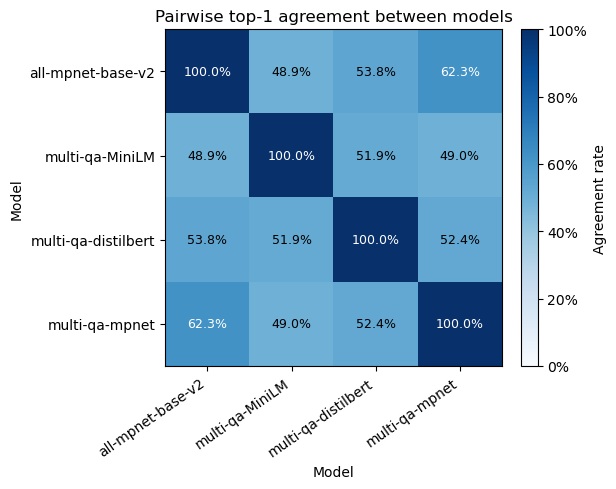

Pairwise rate of any shared top-2 candidate:


,all-mpnet-base-v2,multi-qa-MiniLM,multi-qa-distilbert,multi-qa-mpnet
all-mpnet-base-v2,100.0%,76.5%,81.1%,88.8%
multi-qa-MiniLM,76.5%,100.0%,80.4%,76.7%
multi-qa-distilbert,81.1%,80.4%,100.0%,80.2%
multi-qa-mpnet,88.8%,76.7%,80.2%,100.0%


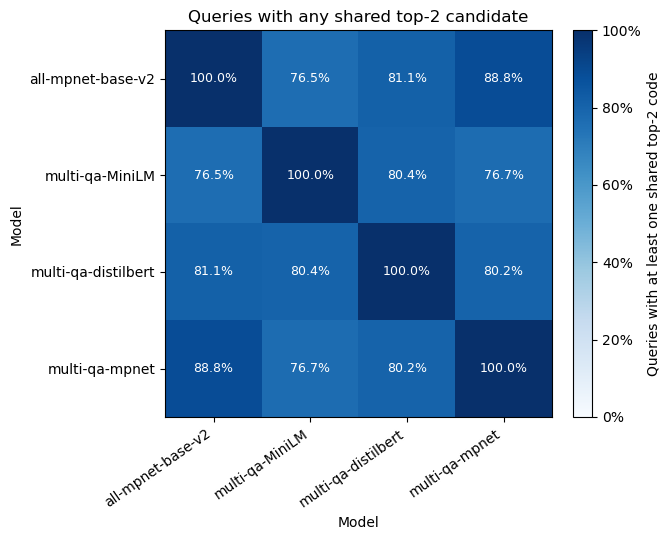

In [113]:
for model in pairwise_agreement.index:
    pairwise_agreement.loc[model, model] = 1.0
display(pairwise_agreement)

# Convert the pairwise-agreement table into a numeric array.
agreement_values = pairwise_agreement.to_numpy(dtype=float)
model_labels = pairwise_agreement.index.tolist()

fig, ax = plt.subplots(figsize=(6.5, 5))

heatmap = ax.imshow(
    agreement_values,
    cmap="Blues",
    vmin=0,
    vmax=1,
)

# Add percentage labels to each cell.
for row in range(len(model_labels)):
    for column in range(len(model_labels)):
        value = agreement_values[row, column]

        ax.text(
            column,
            row,
            f"{value:.1%}",
            ha="center",
            va="center",
            fontsize=9,
            color="white" if value >= 0.60 else "black",
        )

ax.set_xticks(range(len(model_labels)))
ax.set_xticklabels(
    model_labels,
    rotation=35,
    ha="right",
)

ax.set_yticks(range(len(model_labels)))
ax.set_yticklabels(model_labels)

ax.set(
    xlabel="Model",
    ylabel="Model",
    title="Pairwise top-1 agreement between models",
)

# Display the color scale as percentages.
colorbar = fig.colorbar(
    heatmap,
    ax=ax,
    fraction=0.046,
    pad=0.04,
)

colorbar.set_label("Agreement rate")

colorbar_ticks = np.linspace(0, 1, 6)
colorbar.set_ticks(colorbar_ticks)
colorbar.set_ticklabels(
    [f"{value:.0%}" for value in colorbar_ticks]
)

fig.tight_layout()
plt.show()

rate_values = top2_any_overlap_rate.to_numpy(dtype=float)
model_labels = top2_any_overlap_rate.index.tolist()

fig, ax = plt.subplots(figsize=(7, 5.5))

heatmap = ax.imshow(
    rate_values,
    cmap="Blues",
    vmin=0,
    vmax=1,
)

# Show only the percentage of queries with any top-2 overlap.
for row in range(len(model_labels)):
    for column in range(len(model_labels)):
        rate = rate_values[row, column]

        ax.text(
            column,
            row,
            f"{rate:.1%}",
            ha="center",
            va="center",
            fontsize=9,
            color="white" if rate >= 0.60 else "black",
        )

ax.set_xticks(range(len(model_labels)))
ax.set_xticklabels(
    model_labels,
    rotation=35,
    ha="right",
)

ax.set_yticks(range(len(model_labels)))
ax.set_yticklabels(model_labels)

ax.set(
    xlabel="Model",
    ylabel="Model",
    title="Queries with any shared top-2 candidate",
)

colorbar = fig.colorbar(
    heatmap,
    ax=ax,
    fraction=0.046,
    pad=0.04,
)

colorbar.set_label(
    "Queries with at least one shared top-2 code"
)

colorbar_ticks = np.linspace(0, 1, 6)
colorbar.set_ticks(colorbar_ticks)
colorbar.set_ticklabels(
    [f"{value:.0%}" for value in colorbar_ticks]
)

print("Pairwise rate of any shared top-2 candidate:")

display(
    top2_any_overlap_rate.style.format("{:.1%}")
)

fig.tight_layout()
plt.show()

### Pairwise-agreement heatmap

The heatmap compares each pair of models. Each cell reports the percentage of queries for which the two models selected the same top-ranked ISIC code.

Darker cells indicate higher agreement. The off-diagonal cells reveal which models behave most similarly and which model pairs disagree more often.

Pairwise agreement ranged from approximately 48.9% to 62.3%, indicating that no two models produced identical rankings consistently across the full dataset.
At least one top-two candidate was shared for approximately 76.5% to 88.8% of queries. This shows us that models’ leading candidates are fairly consistent, even when the models disagree about which code should be ranked first. The remaining disagreement may also be useful: different models can introduce additional plausible codes into the candidate pool and give reviewers more alternatives to consider.

However, a different candidate is not necessarily a relevant candidate. Top-two overlap measures consistency in model behavior, while human review is still needed to determine which retrieved ISIC codes are appropriate.

Agreement is useful for identifying cases for further review, but it does not measure accuracy. Multiple models can agree on the same incorrect code, so their selections must ultimately be evaluated against human-reviewed labels. In our case, these diagnostics help prioritize cases for the final manual review.

## Data Quality & Evaluation Questions

Use the model outputs and reviewed labels to answer the following questions.

---

### Question 1) Input coverage

- How many association queries were blank or removed?
- How many ISIC descriptions were blank or duplicated?
- Do all expected four-digit ISIC codes retain leading zeros?

---

### Question 2) Model Inspection

- What are the descriptive statistics of rank-2 gaps?
- What patterns of category grouping can we see from the output?

---

### Question 3) Model inspection

- What percentage of queries receive the same rank-1 ISIC code from all four models?
- Which pair of models agrees most often?
- Which focus categories produce the most disagreement?

---

### Question 4) Model Inspection

- How many queries have a rank-1/rank-2 gap below `0.02` (mean, std, etc.)? Do all models return similar metrics?
- Are small-gap queries actually less accurate in the reviewed sample?
- Would a different threshold capture errors more efficiently?

---

### Question 5) Error patterns

- When rank 1 is wrong, is the correct code often present at ranks 2–5?
- Which ISIC classes are commonly confused?
- Are errors concentrated among associations with multiple focus areas?

---

